##### Imports

In [70]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler

### Problématique : quels profils de candidats mettre en avant pour adapter l'action commerciale ?

### Décrire et contrôler les données

#### Lire et contrôler le fichier source

In [71]:
df = pd.read_csv("dossiers_recrutement.csv")
 
print(df.shape)
df.info()

(600, 9)
<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_dossier              600 non-null    str    
 1   annees_experience       600 non-null    float64
 2   salaire_actuel_k        600 non-null    float64
 3   pretention_salariale_k  600 non-null    float64
 4   nb_candidatures_6m      600 non-null    int64  
 5   taux_reponse_pct        600 non-null    float64
 6   score_technique         600 non-null    float64
 7   score_comportemental    600 non-null    float64
 8   delai_disponibilite_j   600 non-null    int64  
dtypes: float64(6), int64(2), str(1)
memory usage: 42.3 KB


In [72]:
var_actives = ["annees_experience", "salaire_actuel_k",
           "pretention_salariale_k", "nb_candidatures_6m",
           "taux_reponse_pct", "delai_disponibilite_j",
           "score_technique", "score_comportemental"]

df_base = df.set_index("id_dossier") 
df_act = df_base[var_actives]

display(df_act)

,annees_experience,salaire_actuel_k,pretention_salariale_k,nb_candidatures_6m,taux_reponse_pct,delai_disponibilite_j,score_technique,score_comportemental
id_dossier,,,,,,,,
CAND-0001,3.2,32.0,42.3,25,71.9,27,67.8,71.3
CAND-0002,15.4,68.7,83.3,4,46.2,96,80.3,75.3
CAND-0003,15.2,68.5,76.4,5,59.3,76,81.8,73.9
CAND-0004,5.5,45.6,53.6,16,83.2,9,75.3,82.6
CAND-0005,15.5,67.3,86.5,4,57.9,65,85.0,76.9
...,...,...,...,...,...,...,...,...
CAND-0596,14.4,69.3,70.1,4,62.0,69,81.1,76.1
CAND-0597,1.2,34.0,40.8,19,66.2,29,54.9,71.9
CAND-0598,8.3,51.5,53.4,3,20.2,61,52.3,46.3


In [73]:
print(df_act.isna().sum().sum() )
print(df_base.duplicated().sum())
print(df_base.index.duplicated().sum())

0
0
0


In [74]:
stats =df_act.describe()
# cv = coefficient de variation = (écart-type / moyenne) * 100
cv = (stats.loc["std"] / stats.loc["mean"]) * 100
stats.loc["cv (%)"] = cv

display(stats.T.round(2))

,count,mean,std,min,25%,50%,75%,max,cv (%)
annees_experience,600.0,8.00,4.80,0.1,4.20,7.55,11.38,20.1,59.95
salaire_actuel_k,600.0,48.16,13.30,25.8,36.80,46.10,56.60,80.2,27.62
pretention_salariale_k,600.0,56.42,14.63,32.3,44.20,53.60,67.53,89.4,25.94
nb_candidatures_6m,600.0,10.64,7.91,1.0,3.00,8.00,17.00,30.0,74.37
taux_reponse_pct,600.0,56.52,23.52,11.4,38.62,61.75,76.35,93.4,41.61
delai_disponibilite_j,600.0,41.64,28.13,0.0,13.75,38.50,68.00,99.0,67.56
score_technique,600.0,68.76,12.27,41.5,58.48,67.90,80.00,96.1,17.85
score_comportemental,600.0,68.28,13.55,34.8,58.90,71.30,78.93,91.6,19.85


Unités et amplitudes très différentes : années, k euros, pourcentages, jours.  
Les distributions viennent d'un mélange de profils, ce que la classification doit justement révéler.

Le coeff. de variation mesure la dispersion d'une variable par rapport à sa moyenne (faible = valeurs proche de la moyenne et inversement si elles sont élevées, alors les valeurs sont dispersées).  

Un CV de 60 % = écart-type représente 60 % de la moyenne.  
Il est surtout utile pour comparer la dispersion relative de variables exprimées dans des unités différentes, pas de seuil universel pour dire qu’un CV est « élevé ».

/!\ Attention : le CV est surtout pertinent si la variable est positive et que sa moyenne n’est pas proche de zéro & le calculer avant centrage-réduction (après standardisation, leur moyenne est proche de zéro, donc le CV n’est plus interprétable).

#### Les distributions

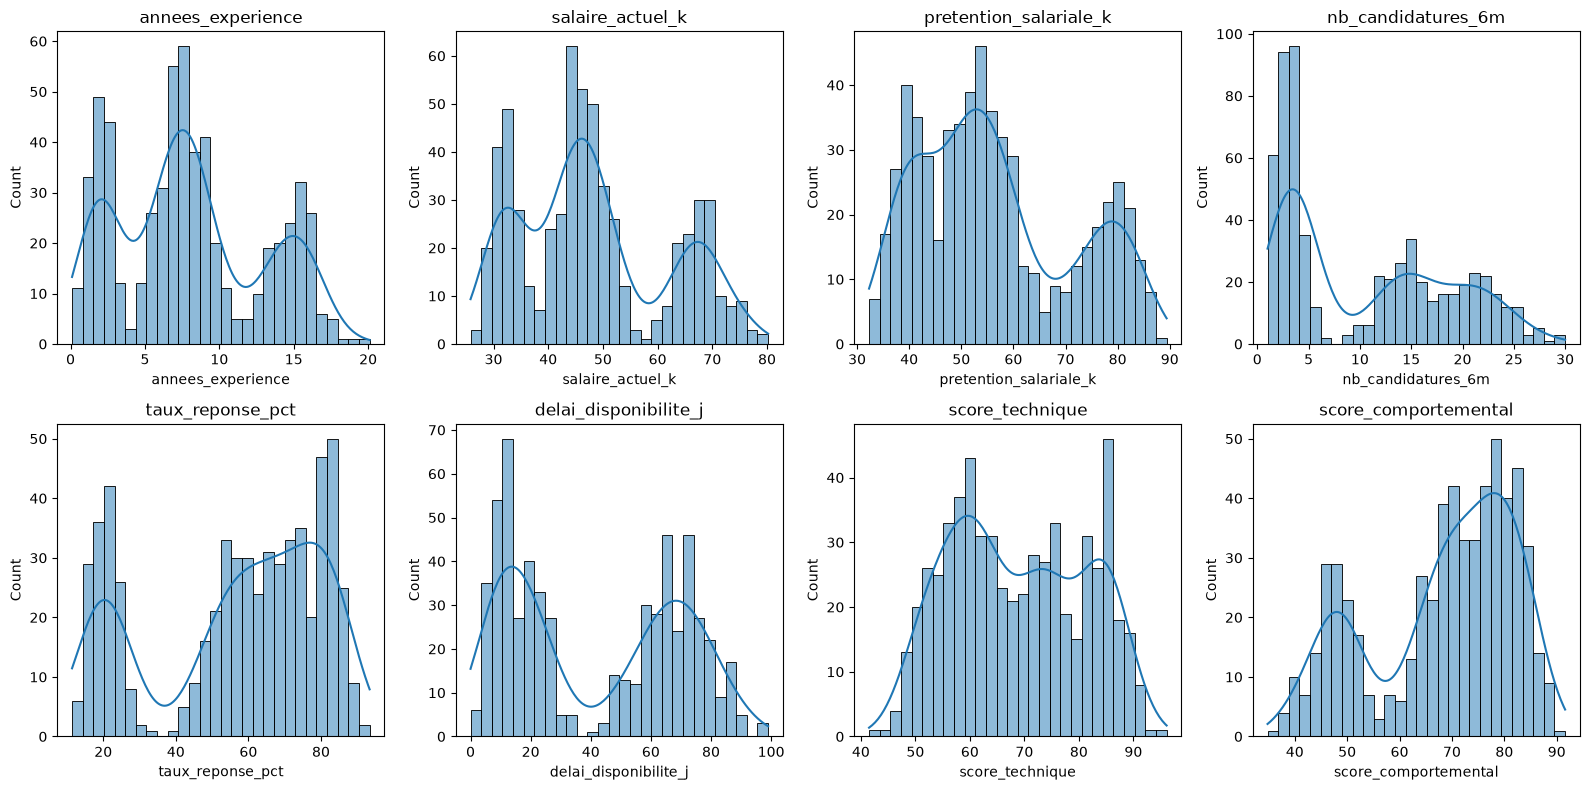

In [75]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for var, ax in zip(var_actives, axes.flat):
    sns.histplot(data=df_act, x=var, kde=True, bins=28, ax=ax)
    # kde à true ajoute une courbe lissée pour visualiser la forme de la distribution
    ax.set_title(var)

plt.tight_layout()
plt.show()

La base de données mélange des profils différents.  
Une population à plusieurs bosses annonce des sous-populations (ce que K-means et la CAH vont isoler)

#### Centrer-réduire et boîtes à moustaches

In [76]:
moyennes = df_act.mean(axis=0)
ecarts = df_act.std(axis=0, ddof=0)

Z = (df_act - moyennes) / ecarts

Centrer : retirer la moyenne  
Réduire : diviser par l'écart-type
⇒ chaque variable à une moyenne 0 et une variance 1 = elles pèsent toutes autant.  

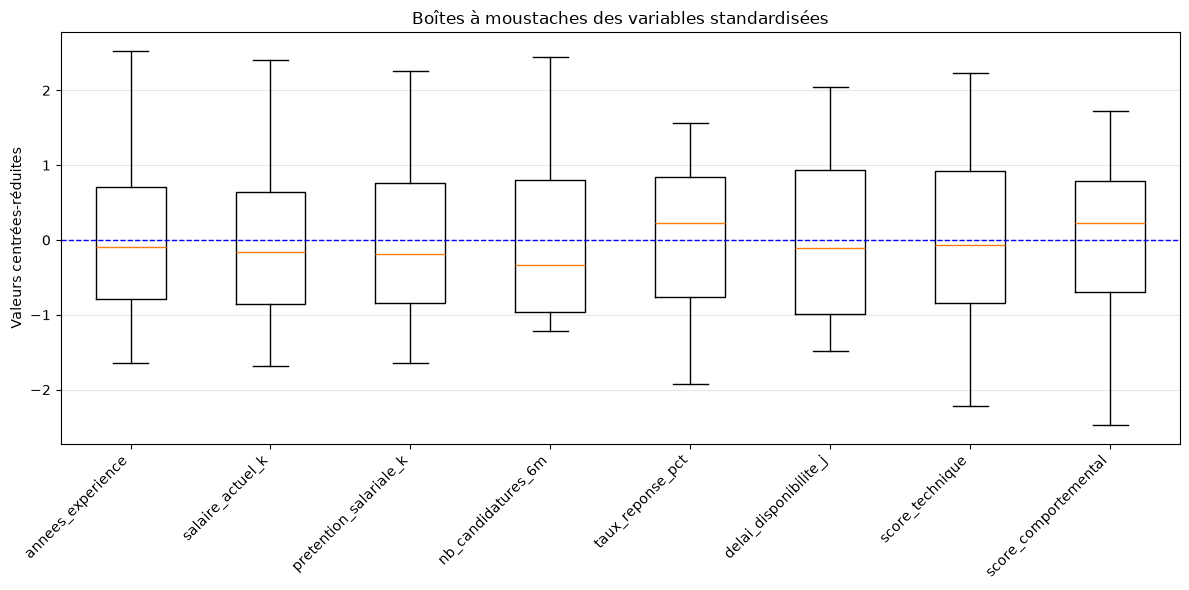

In [77]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.boxplot(Z.values, tick_labels=Z.columns.tolist())
ax.axhline(0, color="blue", linestyle="--", linewidth=1)

ax.set_ylabel("Valeurs centrées-réduites")
ax.set_title("Boîtes à moustaches des variables standardisées")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Assymétrie qand la médiane n'est pas centrée

#### Liaisons entre variables

##### Corrélation de Pearson

In [78]:
corr = df_act.corr(method="pearson") 
# renvoie la matrice de corrélation

# display(corr)

##### Paires par force de liaisons

In [79]:
i, j = np.triu_indices_from(corr, k=1)

liaisons = pd.DataFrame({
    "variable_1": corr.columns.to_numpy()[i],
    "variable_2": corr.columns.to_numpy()[j],
    "correlation": corr.to_numpy()[i, j],
})

liaisons["force"] = liaisons["correlation"].abs()
liaisons = liaisons.dropna(subset=["correlation"])
liaisons = liaisons.sort_values("force", ascending=False)

display(liaisons)

,variable_1,variable_2,correlation,force
0,annees_experience,salaire_actuel_k,0.931072,0.931072
1,annees_experience,pretention_salariale_k,0.896068,0.896068
7,salaire_actuel_k,pretention_salariale_k,0.888116,0.888116
24,taux_reponse_pct,score_comportemental,0.843618,0.843618
19,nb_candidatures_6m,delai_disponibilite_j,-0.805650,0.805650
16,pretention_salariale_k,score_technique,0.784280,0.784280
2,annees_experience,nb_candidatures_6m,-0.767743,0.767743
8,salaire_actuel_k,nb_candidatures_6m,-0.763154,0.763154
10,salaire_actuel_k,delai_disponibilite_j,0.752179,0.752179
4,annees_experience,delai_disponibilite_j,0.730798,0.730798


`np.triu(..., 1)` garde le triangle supérieur, sans la diagonale.
`.where(...).stack() `ne conserve que les paires sélectionnées.  
`.abs().sort_values()` trie les corrélations de la plus forte à la plus faible en ignorant leur signe.  

##### Carte chaleur corrélations

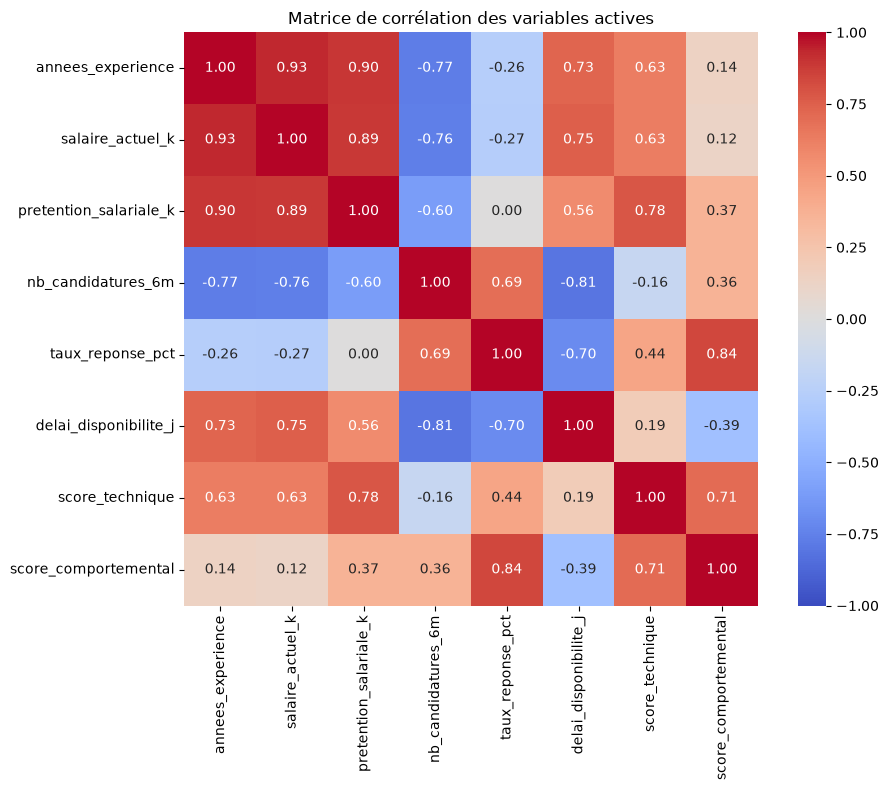

In [80]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,       # affiche les coefficients
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)
plt.title("Matrice de corrélation des variables actives")
plt.tight_layout()
plt.show()

##### Lecture corrélations

La corrélation de Pearson mesure surtout les relations linéaires et ne prouve pas une causalité.

Profil : expérience, salaire actuel et prétention liés positivement (r de 0,89 à 0,93)  
Plus un candidat a d'expérience, moins il dépose de candidatures (r = −0,77)  
Plus le délai de disponibilité est long, moins il y a de candidatures (r = −0,81)  
Taux de réponse et score comportemental : r = 0,84  

En segmentation, les variables fortement corrélées peuvent apporter une information redondante et peser toutes deux dans les distances de k-means = salaire actuel et prétention salariale (r = 0,89) disent presque la même chose : ensemble, elles sur-pondèrent la dimension salariale dans les distances.  

Coorélation entre deux variable :  
- Pearson (linéaire) : mesure si les points suivent à peu près une droite (quand X augmente, Y augmente proportionnellement)  
- Spearman (monotone) : vérifie si Y a tendance à toujours augmenter (ou toujours diminuer) quand X augmente, même si la relation suit une courbe et pas une droite.

⇒ Plusieurs blocs de variables liées : on peut s'attendre à des groupes de candidats bien distincts

##### Bonus : corrélation de Spearman

Si les nuages de points montrent des courbes monotones ou si tu veux réduire l’influence des valeurs extrêmes, on peut regarder Spearman aussi.

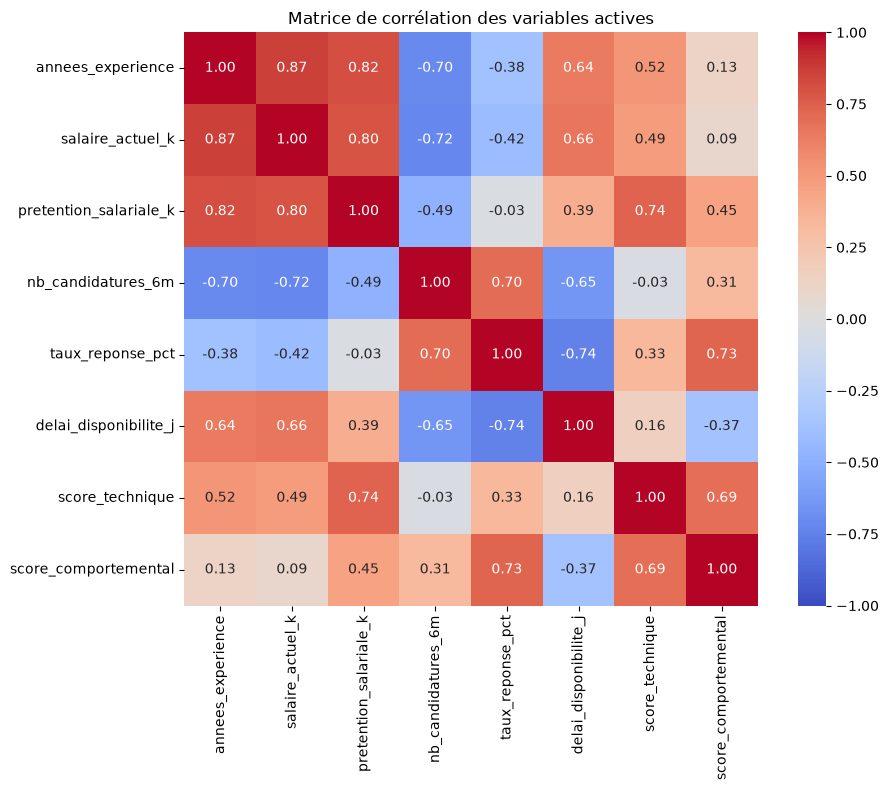

In [81]:
corr_spearman = df_act.corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_spearman,
    annot=True,      
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)
plt.title("Matrice de corrélation des variables actives")
plt.tight_layout()
plt.show()

##### Bonus : nuage de points entre les deux premières variables (voir si des groupes apparaissent)

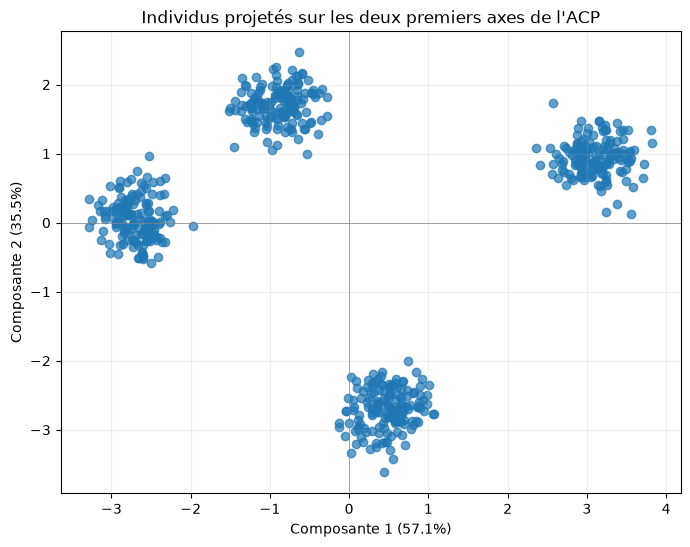

In [82]:
# Z = variables centrées-réduites
pca = PCA(n_components=2)
coord = pca.fit_transform(Z)

plt.figure(figsize=(8, 6))
plt.scatter(coord[:, 0], coord[:, 1], alpha=0.7)
plt.xlabel(f"Composante 1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"Composante 2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("Individus projetés sur les deux premiers axes de l'ACP")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)
plt.grid(alpha=0.2)
plt.show()

### Standardiser les variables

https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

`StandardScaler` calcule et mémorise la moyenne et l’écart-type des données sur lesquelles on l’entraîne + évite la division par zéro.  

On peut donc le stocker dans une variable pour réutiliser ces mêmes valeurs et standardiser les futurs dossiers, afin qu’ils soient mesurés dans le même référentiel que les 600 dossiers initiaux.  

Il ne faut pas faire fit_transform sur les nouveaux dossiers : cela recalculerait moyenne et écart-type, et les distances ne seraient plus comparables à celles utilisées pour créer les groupes.

Tu peux alors consulter les moyennes et échelles apprises avec `scaler.mean_` et `scaler.scale_.`

#### Centrer-réduire (autre méthode moins "manuelle")

In [88]:
scaler = StandardScaler()
# instanciation de l'objet scaler
Z_array = scaler.fit_transform(df_act)
# renvoie un tableau NumPy 
# fit calcule la moyenne et l’écart-type de chaque colonne ;
# transform centre-réduit les valeurs 

In [ ]:
# Plus tard : mêmes colonnes, même ordre
# Z_nouveaux = scaler.transform(df_nouveauxdossiers[var_actives])
# groupes = modele_kmeans.predict(Z_nouveaux)

In [ ]:
Z = pd.DataFrame(
    scaler.fit_transform(df_act),
    index=df_act.index,
    columns=df_act.columns
)

display(Z)

In [89]:
# Avant standardisation
ecart_type_brut = df_act.std(ddof=0)
variance_brute = df_act.var(ddof=0)
part_variance_brute = variance_brute / variance_brute.sum() * 100

# Après standardisation
ecart_type_std = Z.std(ddof=0)
variance_std = Z.var(ddof=0)
part_variance_std = variance_std / variance_std.sum() * 100

tableau = pd.DataFrame({
    "écart-type initial": ecart_type_brut,
    "part variance initiale (%)": part_variance_brute,
    "écart-type standardisé": ecart_type_std,
    "part variance standardisée (%)": part_variance_std,
})

display(tableau.round(2))

,écart-type initial,part variance initiale (%),écart-type standardisé,part variance standardisée (%)
annees_experience,4.79,1.07,1.0,12.5
salaire_actuel_k,13.29,8.21,1.0,12.5
pretention_salariale_k,14.62,9.94,1.0,12.5
nb_candidatures_6m,7.91,2.91,1.0,12.5
taux_reponse_pct,23.50,25.66,1.0,12.5
delai_disponibilite_j,28.11,36.71,1.0,12.5
score_technique,12.26,6.99,1.0,12.5
score_comportemental,13.54,8.52,1.0,12.5


Sans standardisation, le délai (36,7 %) et le taux de réponse (25,7 %) portent 62,4 % de la variance : ils dicteraient les classes. 

/!\ Attention : la part de variance initiale dépend des unités de mesure.  
Une variable exprimée en milliers peut sembler plus importante qu’une variable exprimée en pourcentage simplement à cause de son **échelle**.  
Pour comparer équitablement les variables utilisées ensuite par K-means, la part après standardisation est plus pertinente. C’est la part de variance des variables, pas celle des axes d’une ACP.

### Le K-means

Trouver des groupes en faisant en sorte de minimiser l'inertie intraclasse.  
Ici, une ligne de données = un **dossier** de recrutement, nommé tout le long dossier.

#### Boucle qui teste le K-means optimal

Test k de 2 à 8 et calcule pour chaque valeur l’inertie et le score moyen de silhouette. (1, pas vraiment de segmentation et score de silhouette pas calculable sur un seul groupe)  

`K_OPT `est le k qui maximise la silhouette parmi les valeurs testées, pas nécessairement le nombre de groupes à retenir définitivement.  
L’inertie diminue toujours quand k augmente : on cherche plutôt un « coude » sur sa courbe.  

`KMeans` classe de l'algorithme  
`random_state` fixe une graine pour que les numéros de classes ne changent pas d'une execution à une autre et soit reproductible
`n_init` relance n fois pour garder le meilleur résultat

`.fit` : fait la segmentation = initialise des centres de gravité, affecte chaque dossier au centre le plus proche, recalcule les centres et répète ces étapes jusqu’à stabilisation.  

⇒ toutes les valeurs suivantes sont calculées pour chaque `k`  

`modele.labels_` contient le groupe attribué à chaque dossier donc `modele.labels_[0]` = groupe du premier dossier de Z, ...  
`modele.cluster_centers_` les centres obtenus  
`modele.inertia_` l’inertie finale intra-classe  

`silhouette_score(Z, groupes)` évalue la qualité de cette segmentation : les dossiers sont-ils proches de leur propre groupe et éloignés des autres ? Le score va de −1 à 1 ; plus il est élevé, mieux les groupes sont séparés selon ce critère.  

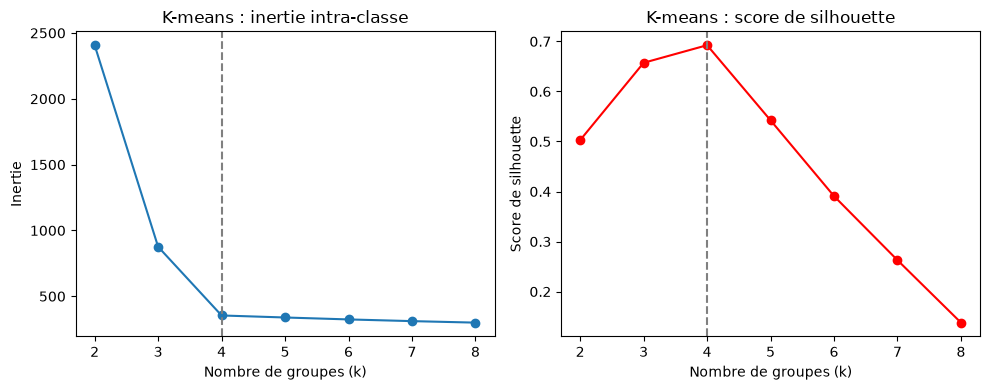

Meilleur k selon la silhouette : 4


,inertie,silhouette_kmeans
k,,
2,2406.933,0.503
3,875.819,0.657
4,354.242,0.692
5,338.875,0.542
6,324.198,0.391
7,311.295,0.263
8,299.877,0.138


In [ ]:
lignes = []

for k in range(2, 9):
    modele = KMeans(n_clusters=k, n_init=20, random_state=17)
    modele.fit(Z)

    lignes.append({
        "k": k,
        "inertie": modele.inertia_, 
        "silhouette_kmeans": silhouette_score(Z, modele.labels_)
    })

res_km = pd.DataFrame(lignes).set_index("k")
K_OPT = int(
    res_km.index.to_numpy(dtype=int)[
        np.argmax(res_km["silhouette_kmeans"].to_numpy())
    ]
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(res_km.index, res_km["inertie"], marker="o")
axes[0].axvline(K_OPT, linestyle="--", color="grey")
axes[0].set_title("K-means : inertie intra-classe")
axes[0].set_xlabel("Nombre de groupes (k)")
axes[0].set_ylabel("Inertie")

axes[1].plot(
    res_km.index,
    res_km["silhouette_kmeans"],
    marker="o",
    color="red"
)
axes[1].axvline(K_OPT, linestyle="--", color="grey")
axes[1].set_title("K-means : score de silhouette")
axes[1].set_xlabel("Nombre de groupes (k)")
axes[1].set_ylabel("Score de silhouette")

plt.tight_layout()
plt.show()

print(f"Meilleur k selon la silhouette : {K_OPT}")
display(res_km.round(3))

#### Choix du K-means appliqué

Après avoir interprété les graphiques et choisi le nombre de groupes, on réentraîne un modèle final.  
Les étiquettes sont bien des numéros pas des catégories avec un ordre particulier.

In [93]:
# Après avoir choisi le nombre de groupes à retenir
K_FINAL = 4

modele_final = KMeans(
    n_clusters=K_FINAL,
    n_init=20,
    random_state=17
)
labels = modele_final.fit_predict(Z)

# Ajouter l'affectation à chaque dossier
df_resultats = df_act.copy()
df_resultats["groupe"] = labels

display(df_resultats.head())

,annees_experience,salaire_actuel_k,pretention_salariale_k,nb_candidatures_6m,taux_reponse_pct,delai_disponibilite_j,score_technique,score_comportemental,groupe
id_dossier,,,,,,,,,
CAND-0001,3.2,32.0,42.3,25,71.9,27,67.8,71.3,3
CAND-0002,15.4,68.7,83.3,4,46.2,96,80.3,75.3,2
CAND-0003,15.2,68.5,76.4,5,59.3,76,81.8,73.9,2
CAND-0004,5.5,45.6,53.6,16,83.2,9,75.3,82.6,1
CAND-0005,15.5,67.3,86.5,4,57.9,65,85.0,76.9,2


L’idée générale est bien d’affecter chaque dossier au centre le plus proche, mais K-means recalcule aussi les centres au fil des itérations pour améliorer les groupes.  

`fit_predict(Z)` entraîne le modèle K-means sur Z, puis renvoie le groupe attribué à chaque dossier. C’est équivalent à  

```bash
modele.fit(Z)
groupes = modele.labels_
```

⇒ entraîne K-means avec k groupes, récupère l’affectation des dossiers, puis calcule le score pour comparer cette valeur de k aux autres.

# CODE de klaus discord + finir note SLIDE 14

In [ ]:
L = linkage(Z, method="ward")
hauteurs = L[:, 2]
seuil = (hauteurs[-4] + hauteurs[-3]) / 2

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
dendrogram(L, truncate_mode="lastp", p=30, color_threshold=seuil,
           no_labels=True, above_threshold_color="grey", ax=axes[0])
axes[0].axhline(seuil, color="black", ls="--", lw=1)
axes[0].set_title("Dendrogramme (30 dernières fusions, coupe à 4 classes)")
axes[0].set_ylabel("distance de Ward")

derniers = hauteurs[-10:][::-1]
axes[1].bar(range(2, 12), derniers, color="lightgreen", edgecolor="black")
axes[1].set_title("Hauteur des 10 dernières fusions")
axes[1].set_xlabel("nombre de classes avant la fusion")
plt.tight_layout()
plt.show()

In [ ]:
lignes = []
for k in K_RANGE:
    lab = fcluster(L, k, criterion="maxclust")
    lignes.append({"k": k, "silhouette_cah": silhouette_score(Z, lab)})
res_cah = pd.DataFrame(lignes).set_index("k")

cah_brut = fcluster(L, 4, criterion="maxclust")
df["cluster_cah_brut"] = cah_brut
res_cah.round(3)